In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from itertools import product
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings('ignore')


  SOUS-GROUPE : RUT  |  Actifs : ['^RUT']
  ^RUT     | IS  Sharpe= 0.344 Return=   4.2% | OOS Sharpe= 9.074 Return=  69.9%

  SOUS-GROUPE : Commodities  |  Actifs : ['GC=F', 'CL=F']
  GC=F     | IS  Sharpe= 0.309 Return=   3.3% | OOS Sharpe= 4.557 Return=  32.6%
  CL=F     | IS  Sharpe= 1.967 Return=  55.1% | OOS Sharpe= 8.551 Return= 143.6%

  SOUS-GROUPE : Autres_Indices  |  Actifs : ['^GSPC', '^DJI', 'QQQ']
  ^GSPC    | IS  Sharpe=-0.876 Return= -19.6% | OOS Sharpe= 2.238 Return=  14.1%
  ^DJI     | IS  Sharpe=-1.343 Return= -27.2% | OOS Sharpe=-0.792 Return=  -5.8%
  QQQ      | IS  Sharpe= 1.261 Return=  28.2% | OOS Sharpe= 2.035 Return=  16.3%

  PORTEFEUILLE GLOBAL – IS vs OOS
  PORTEFEUILLE | IS  Sharpe= 0.729 Return=   6.6% MaxDD= -4.3%
  PORTEFEUILLE | OOS Sharpe= 7.973 Return=  41.3% MaxDD= -0.5%

           IS Sharpe  OOS Sharpe  IS Return%  OOS Return%  IS MaxDD%  OOS MaxDD%
Asset                                                                           
^RUT           0.0

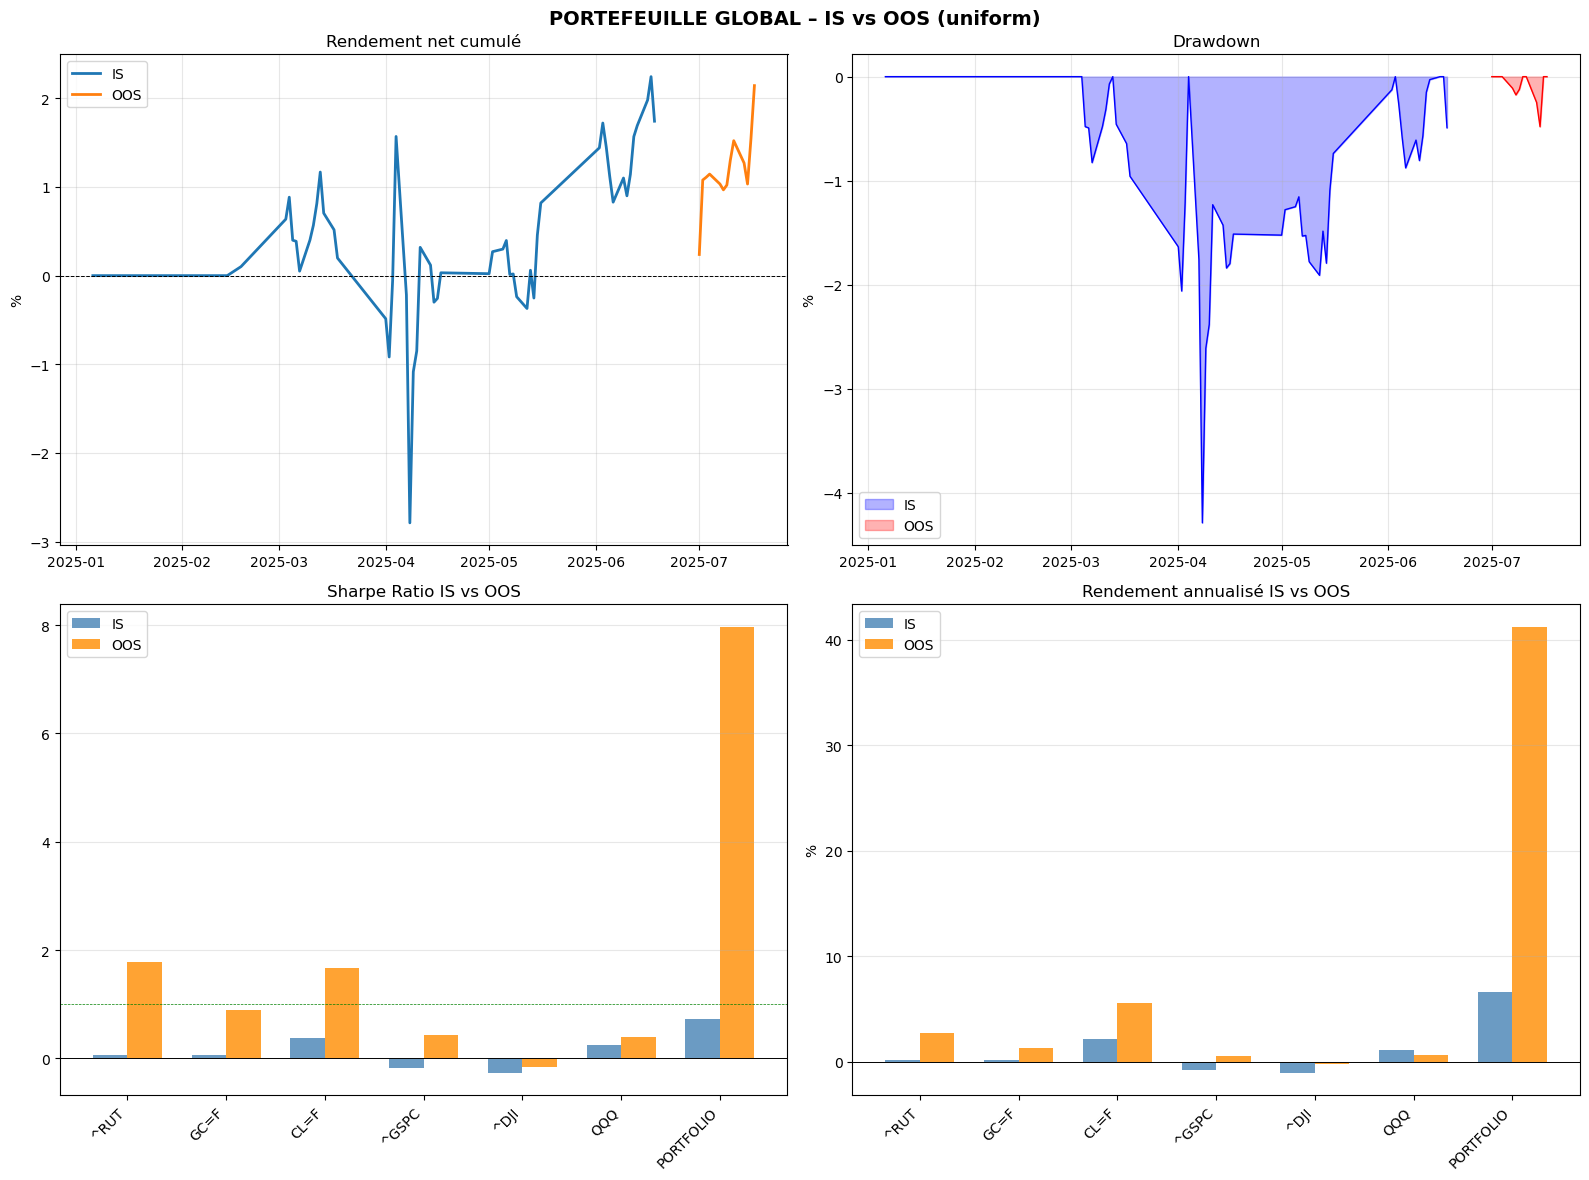

In [3]:
def get_bars_per_year(freq):
    return {'1min':252*390,'5min':252*78,'15min':252*26,'30min':252*13,'1H':252*6,'1D':252}.get(freq,252*26)

def generate_weights(n, method='uniform'):
    if n<=0: return np.array([])
    if method=='uniform': return np.ones(n)/n
    if method=='linear': w=np.arange(1,n+1,dtype=float); return w/w.sum()
    if method=='exponential': w=np.exp(np.linspace(0,1,n)); return w/w.sum()

def normalize(t): return t.replace("^","").replace("=F","F").replace("=X","X")

def load_data(path, tickers):
    raw={t:[] for t in tickers}
    for day in sorted(os.listdir(path)):
        if not day.startswith("Yahoo_1m"): continue
        dp=os.path.join(path,day)
        if not os.path.isdir(dp): continue
        for f in os.listdir(dp):
            if not f.startswith("df_") or not f.endswith(".pkl"): continue
            ft=f.replace(".pkl","").split("_")[1]
            for t in tickers:
                if normalize(t)==ft: raw[t].append(pd.read_pickle(os.path.join(dp,f)))
    data={}
    for t,frames in raw.items():
        if not frames: continue
        df=pd.concat(frames).sort_index()
        df=df[~df.index.duplicated(keep='first')]
        if isinstance(df.columns,pd.MultiIndex): df.columns=[c[0] for c in df.columns]
        df.columns=[str(c).capitalize() for c in df.columns]
        if df.index.tz is not None: df.index=df.index.tz_convert("America/New_York")
        if '=F' not in t: df=df.between_time("09:30","16:00")
        data[t]=df
    return data

def resample_data(df, freq='15min'):
    if freq is None: return df
    if not df.index.is_monotonic_increasing: df=df.sort_index()
    return df.resample(freq).agg({'Open':'first','High':'max','Low':'min','Close':'last'}).dropna()

def metrics(pnl, freq):
    r=pnl.dropna()
    if len(r)<10: return {k:np.nan for k in ['Ann. Return (%)','Ann. Vol (%)','Ann. Sharpe','Ann. Sortino','Max DD (%)','Win Rate (%)']}
    ann_ret=r.mean()*freq; ann_vol=r.std()*np.sqrt(freq)
    sharpe=ann_ret/ann_vol if ann_vol>0 else np.nan
    downside=r[r<0]; sortino=ann_ret/(downside.std()*np.sqrt(freq)) if len(downside)>1 else np.nan
    cum=(1+r).cumprod(); max_dd=((cum/cum.cummax())-1).min()
    active=r[r!=0]; win_rate=(active>0).mean() if len(active)>0 else 0.0
    return {'Ann. Return (%)':round(ann_ret*100,2),'Ann. Vol (%)':round(ann_vol*100,2),
            'Ann. Sharpe':round(sharpe,3),'Ann. Sortino':round(sortino,3),
            'Max DD (%)':round(max_dd*100,2),'Win Rate (%)':round(win_rate*100,1)}

def avg_trades(df):
    c=df['position'].diff().abs()>1e-4
    return round(c.groupby(df.index.date).sum().mean(),1) if len(c)>0 else 0

def total_trades(df): return int((df['position'].diff().abs()>1e-4).sum())

def run_strategy(df, params, ticker):
    df=df.copy()
    f=params['fast']; s=params['slow']; db=params['deadband']
    tf=params.get('trend_filter',True); df_=params.get('direction_filter',False)
    tt=params.get('trend_threshold',0.001); uts=params.get('use_trailing_stop',True)
    tsp=params.get('trailing_stop_pct',0.005); mbt=params.get('min_bars_between_trades',3)
    scb=params.get('signal_confirmation_bars',2); mtpd=params.get('max_trades_per_day',3)
    abmf=params.get('apply_bear_market_filter',False); bp=params.get('basis_point',0.0001)

    df['ema_fast']=df['Close'].ewm(span=f,adjust=False).mean()
    df['ema_slow']=df['Close'].ewm(span=s,adjust=False).mean()
    df['ratio']=df['ema_fast']/df['ema_slow']-1.0
    df['tf_flag']=True
    if tf:
        df['ema_ultra']=df['Close'].ewm(span=s*3,adjust=False).mean()
        df['tf_flag']=(abs(df['ema_fast']-df['ema_ultra'])/df['ema_ultra'])>tt
    df['lt_trend']=0
    if df_:
        df['ema_lt']=df['Close'].ewm(span=s*2,adjust=False).mean()
        df['lt_trend']=np.where(df['Close']>df['ema_lt'],1,-1)
    df['market_regime']=1
    if abmf:
        dc=df['Close'].resample('1D').last().dropna()
        if len(dc)>=200:
            sma=dc.rolling(200,min_periods=50).mean()
            sma=sma.reindex(df.index.date,method='ffill'); sma.index=df.index
            df['market_regime']=np.where(df['Close']>sma,1,-1)
    df['signal_raw']=0
    df.loc[df['ratio']>db,'signal_raw']=1; df.loc[df['ratio']<-db,'signal_raw']=-1
    df.loc[~df['tf_flag'],'signal_raw']=np.nan
    if df_: df.loc[(df['signal_raw']==1)&(df['lt_trend']!=1),'signal_raw']=np.nan; df.loc[(df['signal_raw']==-1)&(df['lt_trend']!=-1),'signal_raw']=np.nan
    if abmf: df.loc[(df['signal_raw']==1)&(df['market_regime']!=1),'signal_raw']=np.nan; df.loc[(df['signal_raw']==-1)&(df['market_regime']!=-1),'signal_raw']=np.nan
    df['signal_raw']=df['signal_raw'].replace(0,np.nan)
    if scb>1:
        c=df['signal_raw'].copy()
        for sh in range(1,scb): c=c.where(c==df['signal_raw'].shift(sh),np.nan)
        df['signal_confirmed']=c
    else: df['signal_confirmed']=df['signal_raw']
    df['signal']=df['signal_confirmed'].ffill().fillna(0)
    df['position_raw']=df['signal'].shift(1).fillna(0)
    il=df.index.date!=np.roll(np.array(df.index.date),-1); il[-1]=True; df.loc[il,'position_raw']=0.0
    pr=df['position_raw'].values.copy(); dates=np.array([d.date() for d in df.index])
    tb=-999; ttd=0; cd=None
    for i in range(1,len(df)):
        if dates[i]!=cd: cd=dates[i]; ttd=0
        if abs(pr[i]-pr[i-1])>1e-6 and abs(pr[i-1])>1e-6: tb=i; ttd+=1
        if abs(pr[i])>1e-6 and abs(pr[i-1])<1e-6:
            if i-tb<mbt: pr[i]=0.0; continue
            if ttd>=mtpd: pr[i]=0.0; continue
            ttd+=1; tb=i
    df['position']=pr
    pos=df['position'].values.copy(); closes=df['Close'].values
    ep=np.nan; es=0; sp=np.nan; df_flat=False; cur_d=None
    for i in range(1,len(df)):
        if dates[i]!=cur_d: cur_d=dates[i]; ep=np.nan; es=0; sp=np.nan; df_flat=False
        if df_flat: pos[i]=0.0; continue
        if pos[i]!=0 and es==0:
            es=int(np.sign(pos[i])); ep=closes[i-1]
            if uts: sp=ep*(1-tsp) if es==1 else ep*(1+tsp)
        elif es!=0 and uts:
            if es==1:
                if closes[i]>ep: sp=max(sp,closes[i]*(1-tsp)) if not np.isnan(sp) else closes[i]*(1-tsp)
                hit=closes[i]<=sp
            else:
                if closes[i]<ep: sp=min(sp,closes[i]*(1+tsp)) if not np.isnan(sp) else closes[i]*(1+tsp)
                hit=closes[i]>=sp
            if hit: pos[i]=0.0; es=0; ep=np.nan; sp=np.nan; df_flat=True
    df['position']=pos
    S=df['Close']; df['ret']=S.pct_change()
    df['pnl_gross']=(df['position'].shift(1)*df['ret']).fillna(0)
    delta=df['position'].diff().abs()
    df['fees_ret']=(delta*bp*(S.shift(1)+S)/S.shift(1)).fillna(0)
    df['pnl_net']=(df['pnl_gross']-df['fees_ret']).replace([np.inf,-np.inf],np.nan)
    return df

def grid_search(df_is, ticker, gp, sp):
    fr=gp['fast_range']; sr=gp['slow_range']; dr=gp['deadband_range']
    tfo=gp['trend_filter_options']; dfo=gp['direction_filter_options']
    sc=gp.get('sharpe_cap',3.0); rw=gp.get('return_weight',0.3)
    best_score=-np.inf; best_params=None
    combos=list(product(fr,sr,dr,tfo,dfo))
    for i,(f,s,db,tf_,df_) in enumerate(combos):
        if f>=s: continue
        try:
            p=sp.copy(); p.update({'fast':f,'slow':s,'deadband':db,'trend_filter':tf_,'direction_filter':df_})
            d=run_strategy(df_is,p,ticker); m=metrics(d['pnl_net'],p['bars_per_year'])
            s_=m['Ann. Sharpe']; ret=m['Ann. Return (%)']
            s_adj=s_ if (np.isfinite(s_) and s_<=sc) else (sc-(s_-sc)*0.5 if np.isfinite(s_) else -np.inf)
            score=s_adj+rw*(ret/100) if (np.isfinite(s_adj) and np.isfinite(ret)) else -np.inf
            if score>best_score: best_score=score; best_params=p.copy()
        except: continue
    return best_params, best_score

def cross_validate(df, ticker, gp, sp, n_splits=3):
    tscv=TimeSeriesSplit(n_splits=n_splits,test_size=int(len(df)*0.2))
    rw=gp.get('return_weight',0.3); best_mean=-np.inf; best_params=None
    combos=[(f,s,db) for f,s,db in product(gp['fast_range'],gp['slow_range'],gp['deadband_range']) if f<s]
    for f,s,db in combos:
        oos_scores=[]; base=sp.copy(); base.update({'fast':f,'slow':s,'deadband':db})
        for ti,tei in tscv.split(df):
            tr,te=df.iloc[ti],df.iloc[tei]; best_fold=-np.inf; bfp=None
            for tf_,df_ in product(gp['trend_filter_options'],gp['direction_filter_options']):
                try:
                    p=base.copy(); p.update({'trend_filter':tf_,'direction_filter':df_})
                    tmp=run_strategy(tr,p,ticker); m=metrics(tmp['pnl_net'],p['bars_per_year'])
                    sc=m['Ann. Sharpe']+rw*(m['Ann. Return (%)']/100) if (np.isfinite(m['Ann. Sharpe']) and np.isfinite(m['Ann. Return (%)'])) else -np.inf
                    if sc>best_fold: best_fold=sc; bfp=p.copy()
                except: continue
            if bfp:
                try:
                    te_=run_strategy(te,bfp,ticker); m=metrics(te_['pnl_net'],bfp['bars_per_year'])
                    if np.isfinite(m['Ann. Sharpe']) and np.isfinite(m['Ann. Return (%)']): oos_scores.append(m['Ann. Sharpe']+rw*(m['Ann. Return (%)']/100))
                except: continue
        if oos_scores and np.mean(oos_scores)>best_mean: best_mean=np.mean(oos_scores); best_params=bfp
    return best_params if best_params else sp.copy()

def run_subgroup(params, tag):
    path=params['path']; portfolio=params['portfolio']
    freq=params.get('resample_freq','15min'); oos_m=params.get('oos_months',3)
    bp=params.get('basis_point',0.0001); uts=params.get('use_trailing_stop',True)
    tse=params.get('trailing_stop_pct_eq',0.002); tsc=params.get('trailing_stop_pct_cm',0.05)
    mbt=params.get('min_bars_between_trades',3); scb=params.get('signal_confirmation_bars',2)
    mtpd=params.get('max_trades_per_day',3); bmc=params.get('bear_market_filter_commodities',True)
    bme=params.get('bear_market_filter_equities',False); opt=params.get('optimise',True)
    cv=params.get('use_cross_validation',True); gp=params.get('grid_params',{})
    mib=params.get('min_is_bars',500); bpy=get_bars_per_year(freq)
    suffix=f"_{tag}"

    sdp={'use_trailing_stop':uts,'min_bars_between_trades':mbt,'signal_confirmation_bars':scb,
         'max_trades_per_day':mtpd,'trend_threshold':0.001,'basis_point':bp,'bars_per_year':bpy,
         'trailing_stop_pct_eq':tse,'trailing_stop_pct_cm':tsc}

    print(f"\n{'='*60}\n  SOUS-GROUPE : {tag}  |  Actifs : {portfolio}\n{'='*60}")
    data=load_data(path,portfolio); oos_results={}; is_data={}
    for ticker in portfolio:
        if ticker not in data: continue
        df=data[ticker]
        if df is None or df.empty: continue
        df=resample_data(df,freq)
        if df is None or df.empty or len(df)==0: continue
        ld=df.index[-1]; oos_s=pd.Timestamp(year=ld.year,month=ld.month,day=1,tz=df.index.tz)
        if oos_m>1: oos_s=(oos_s-pd.DateOffset(months=oos_m-1)).replace(day=1)
        df_is=df[df.index<oos_s]; df_oos=df[df.index>=oos_s]
        if len(df_oos)<10: oos_s=pd.Timestamp(year=ld.year,month=ld.month,day=1,tz=df.index.tz); df_is=df[df.index<oos_s]; df_oos=df[df.index>=oos_s]
        if len(df_is)<mib: continue
        ic='=F' in ticker; ab=bmc if ic else bme; ts_=tsc if ic else tse
        sp_=sdp.copy(); sp_.update({'apply_bear_market_filter':ab,'trailing_stop_pct':ts_,'ticker':ticker})
        bp_=cross_validate(df_is,ticker,gp,sp_) if (opt and cv and len(df_is)>500) else (grid_search(df_is,ticker,gp,sp_)[0] if opt else sp_)
        if bp_ is None: bp_=sp_; bp_.update({'fast':5,'slow':20,'deadband':0.0005,'trend_filter':True,'direction_filter':False})
        df_full=run_strategy(df,bp_,ticker)
        df_oos_=df_full[df_full.index>=oos_s].copy(); df_is_=df_full[df_full.index<oos_s].copy()
        mi=metrics(df_is_['pnl_net'],bpy); mo=metrics(df_oos_['pnl_net'],bpy)
        print(f"  {ticker:8s} | IS  Sharpe={mi['Ann. Sharpe']:6.3f} Return={mi['Ann. Return (%)']:6.1f}% | OOS Sharpe={mo['Ann. Sharpe']:6.3f} Return={mo['Ann. Return (%)']:6.1f}%")
        oos_results[ticker]={'df_oos':df_oos_,'params':bp_}; is_data[ticker]={'df_is':df_is_,'params':bp_}
    return oos_results, is_data

def aggregate_global(all_oos, all_is, weights_method='uniform', tag="Global"):
    suffix=f"_{tag}"
    print(f"\n{'='*60}\n  PORTEFEUILLE GLOBAL – IS vs OOS\n{'='*60}")
    all_tickers=list(all_oos.keys())
    # OOS
    daily_oos={t:all_oos[t]['df_oos'].groupby(all_oos[t]['df_oos'].index.date)['pnl_net'].sum() for t in all_tickers}
    port_oos=pd.DataFrame(daily_oos).fillna(0); w=generate_weights(len(all_tickers),weights_method)
    port_oos['portfolio']=port_oos[all_tickers].dot(w)
    # IS
    daily_is={}; is_index=None
    for t in all_tickers:
        s=all_is[t]['df_is']['pnl_net'].groupby(all_is[t]['df_is'].index.date).sum()
        daily_is[t]=s
        if is_index is None: is_index=s.index
    port_is=pd.DataFrame(daily_is).fillna(0)
    port_is['portfolio']=port_is[all_tickers].dot(w)
    
    m_oos=metrics(port_oos['portfolio'],252); m_is=metrics(port_is['portfolio'],252)
    print(f"  PORTEFEUILLE | IS  Sharpe={m_is['Ann. Sharpe']:6.3f} Return={m_is['Ann. Return (%)']:6.1f}% MaxDD={m_is['Max DD (%)']:5.1f}%")
    print(f"  PORTEFEUILLE | OOS Sharpe={m_oos['Ann. Sharpe']:6.3f} Return={m_oos['Ann. Return (%)']:6.1f}% MaxDD={m_oos['Max DD (%)']:5.1f}%")
    
    # Tableau
    rows=[]
    for t in all_tickers:
        mo=metrics(all_oos[t]['df_oos']['pnl_net'],252); mi_=metrics(all_is[t]['df_is']['pnl_net'],252)
        rows.append({'Asset':t,'IS Sharpe':mi_['Ann. Sharpe'],'OOS Sharpe':mo['Ann. Sharpe'],
                     'IS Return%':mi_['Ann. Return (%)'],'OOS Return%':mo['Ann. Return (%)'],
                     'IS MaxDD%':mi_['Max DD (%)'],'OOS MaxDD%':mo['Max DD (%)']})
    rows.append({'Asset':'PORTFOLIO','IS Sharpe':m_is['Ann. Sharpe'],'OOS Sharpe':m_oos['Ann. Sharpe'],
                 'IS Return%':m_is['Ann. Return (%)'],'OOS Return%':m_oos['Ann. Return (%)'],
                 'IS MaxDD%':m_is['Max DD (%)'],'OOS MaxDD%':m_oos['Max DD (%)']})
    table=pd.DataFrame(rows).set_index('Asset')
    print(f"\n{table.to_string()}")
    table.to_csv(f"performance_IS_vs_OOS_{tag}.csv")
    
    # Graphique IS vs OOS
    fig,axes=plt.subplots(2,2,figsize=(16,12))
    fig.suptitle(f"PORTEFEUILLE GLOBAL – IS vs OOS ({weights_method})",fontsize=14,fontweight='bold')
    colors=['navy','crimson']
    # Equity curves
    for ax,port,label in [(axes[0,0],port_is,'IS'),(axes[0,0],port_oos,'OOS')]:
        cum=(1+port['portfolio']).cumprod()-1; ax.plot(cum.index,cum*100,label=label,linewidth=2)
    axes[0,0].axhline(0,color='black',ls='--',lw=0.7); axes[0,0].set_title("Rendement net cumulé"); axes[0,0].legend()
    axes[0,0].set_ylabel("%"); axes[0,0].grid(alpha=0.3)
    # Drawdown
    for ax,port,label,c in [(axes[0,1],port_is,'IS','blue'),(axes[0,1],port_oos,'OOS','red')]:
        cum=(1+port['portfolio']).cumprod(); dd=(cum/cum.cummax()-1)*100
        ax.fill_between(port.index,dd,0,alpha=0.3,color=c,label=label); ax.plot(port.index,dd,color=c,lw=1)
    axes[0,1].set_title("Drawdown"); axes[0,1].legend(); axes[0,1].set_ylabel("%"); axes[0,1].grid(alpha=0.3)
    # Barplot Sharpe
    labels=list(all_tickers)+['PORTFOLIO']
    is_sh=[metrics(all_is[t]['df_is']['pnl_net'],252)['Ann. Sharpe'] for t in all_tickers]+[m_is['Ann. Sharpe']]
    oos_sh=[metrics(all_oos[t]['df_oos']['pnl_net'],252)['Ann. Sharpe'] for t in all_tickers]+[m_oos['Ann. Sharpe']]
    x=np.arange(len(labels)); w_=0.35
    axes[1,0].bar(x-w_/2,is_sh,w_,label='IS',color='steelblue',alpha=0.8)
    axes[1,0].bar(x+w_/2,oos_sh,w_,label='OOS',color='darkorange',alpha=0.8)
    axes[1,0].axhline(0,color='black',lw=0.7); axes[1,0].axhline(1,color='green',ls='--',lw=0.5)
    axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(labels,rotation=45,ha='right')
    axes[1,0].set_title("Sharpe Ratio IS vs OOS"); axes[1,0].legend(); axes[1,0].grid(axis='y',alpha=0.3)
    # Barplot Return
    is_ret=[metrics(all_is[t]['df_is']['pnl_net'],252)['Ann. Return (%)'] for t in all_tickers]+[m_is['Ann. Return (%)']]
    oos_ret=[metrics(all_oos[t]['df_oos']['pnl_net'],252)['Ann. Return (%)'] for t in all_tickers]+[m_oos['Ann. Return (%)']]
    axes[1,1].bar(x-w_/2,is_ret,w_,label='IS',color='steelblue',alpha=0.8)
    axes[1,1].bar(x+w_/2,oos_ret,w_,label='OOS',color='darkorange',alpha=0.8)
    axes[1,1].axhline(0,color='black',lw=0.7)
    axes[1,1].set_xticks(x); axes[1,1].set_xticklabels(labels,rotation=45,ha='right')
    axes[1,1].set_title("Rendement annualisé IS vs OOS"); axes[1,1].legend(); axes[1,1].set_ylabel("%"); axes[1,1].grid(axis='y',alpha=0.3)
    plt.tight_layout(); plt.savefig(f"IS_vs_OOS_Global{suffix}.png",dpi=150); plt.show(); plt.close()
    return port_oos, table

if __name__=="__main__":
    BASE="Data"  # folder of Yahoo 1-minute .pkl files, see README
    
    # Sous-groupe 1 : RUT
    oos1,is1=run_subgroup({'path':BASE,'portfolio':['^RUT'],'resample_freq':'15min','oos_months':1,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.002,'trailing_stop_pct_cm':0.03,
        'min_bars_between_trades':3,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':False,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.0005,0.0035,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"RUT")
    
    # Sous-groupe 2 : Commodities
    oos2,is2=run_subgroup({'path':BASE,'portfolio':['GC=F','CL=F'],'resample_freq':'15min','oos_months':1,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.002,'trailing_stop_pct_cm':0.04,
        'min_bars_between_trades':2,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':True,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.0005,0.0035,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"Commodities")
    
    # Sous-groupe 3 : Autres indices
    oos3,is3=run_subgroup({'path':BASE,'portfolio':['^GSPC','^DJI','QQQ'],'resample_freq':'15min','oos_months':1,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.045,'trailing_stop_pct_cm':0.05,
        'min_bars_between_trades':2,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':False,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.001,0.01,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"Autres_Indices")
    
    # Agrégation globale avec comparaison IS vs OOS
    all_oos={**oos1,**oos2,**oos3}; all_is={**is1,**is2,**is3}
    aggregate_global(all_oos,all_is,'uniform',"Global")


  SOUS-GROUPE : RUT  |  Actifs : ['^RUT']
  ^RUT     | IS  Sharpe= 0.296 Return=   4.1% | OOS Sharpe= 3.441 Return=  21.4%

  SOUS-GROUPE : Commodities  |  Actifs : ['GC=F', 'CL=F']
  GC=F     | IS  Sharpe= 1.360 Return=  14.8% | OOS Sharpe=-0.659 Return=  -5.2%
  CL=F     | IS  Sharpe= 1.499 Return=  43.1% | OOS Sharpe= 5.321 Return= 116.0%

  SOUS-GROUPE : Autres_Indices  |  Actifs : ['^GSPC', '^DJI', 'QQQ']
  ^GSPC    | IS  Sharpe=-1.038 Return= -26.5% | OOS Sharpe= 0.938 Return=   6.9%
  ^DJI     | IS  Sharpe= 0.969 Return=  22.8% | OOS Sharpe= 0.432 Return=   3.3%
  QQQ      | IS  Sharpe=-1.522 Return= -35.8% | OOS Sharpe= 0.472 Return=   4.4%

  PORTEFEUILLE GLOBAL – IS vs OOS
  PORTEFEUILLE | IS  Sharpe= 0.055 Return=   0.5% MaxDD= -4.3%
  PORTEFEUILLE | OOS Sharpe= 4.406 Return=  23.5% MaxDD= -0.9%

           IS Sharpe  OOS Sharpe  IS Return%  OOS Return%  IS MaxDD%  OOS MaxDD%
Asset                                                                           
^RUT           0.0

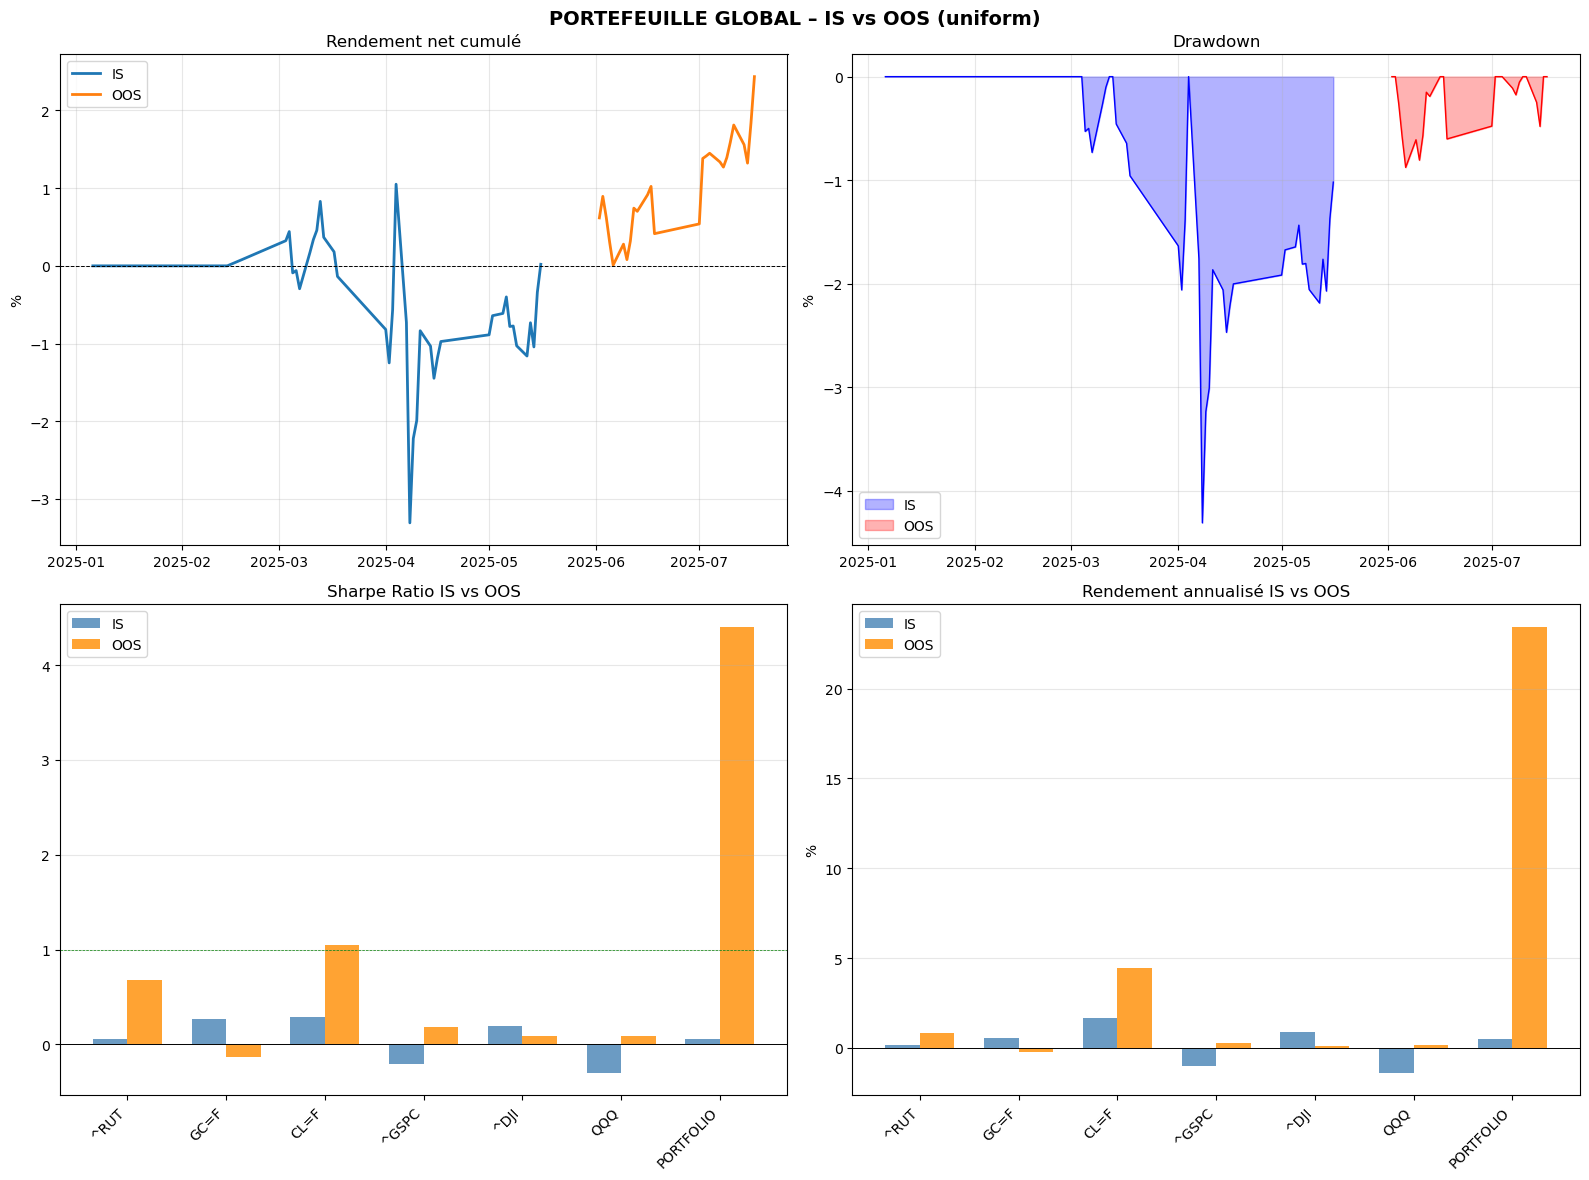

In [4]:
if __name__=="__main__":
    BASE="Data"  # folder of Yahoo 1-minute .pkl files, see README
    
    # Sous-groupe 1 : RUT
    oos1,is1=run_subgroup({'path':BASE,'portfolio':['^RUT'],'resample_freq':'15min','oos_months':2,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.002,'trailing_stop_pct_cm':0.03,
        'min_bars_between_trades':3,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':False,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.0005,0.0035,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"RUT")
    
    # Sous-groupe 2 : Commodities
    oos2,is2=run_subgroup({'path':BASE,'portfolio':['GC=F','CL=F'],'resample_freq':'15min','oos_months':2,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.002,'trailing_stop_pct_cm':0.04,
        'min_bars_between_trades':2,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':True,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.0005,0.0035,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"Commodities")
    
    # Sous-groupe 3 : Autres indices
    oos3,is3=run_subgroup({'path':BASE,'portfolio':['^GSPC','^DJI','QQQ'],'resample_freq':'15min','oos_months':2,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.045,'trailing_stop_pct_cm':0.05,
        'min_bars_between_trades':2,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':False,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.001,0.01,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"Autres_Indices")
    
    # Agrégation globale avec comparaison IS vs OOS
    all_oos={**oos1,**oos2,**oos3}; all_is={**is1,**is2,**is3}
    aggregate_global(all_oos,all_is,'uniform',"Global")


  SOUS-GROUPE : RUT  |  Actifs : ['^RUT']
  ^RUT     | IS  Sharpe= 0.113 Return=   1.8% | OOS Sharpe=-2.031 Return= -14.3%

  SOUS-GROUPE : Commodities  |  Actifs : ['GC=F', 'CL=F']
  GC=F     | IS  Sharpe= 1.115 Return=  12.7% | OOS Sharpe=-0.392 Return=  -3.5%
  CL=F     | IS  Sharpe= 2.014 Return=  61.7% | OOS Sharpe= 3.542 Return=  74.2%

  SOUS-GROUPE : Autres_Indices  |  Actifs : ['^GSPC', '^DJI', 'QQQ']
  ^GSPC    | IS  Sharpe= 0.772 Return=  20.2% | OOS Sharpe= 2.087 Return=  19.1%
  ^DJI     | IS  Sharpe= 0.604 Return=  14.3% | OOS Sharpe= 1.165 Return=  10.4%
  QQQ      | IS  Sharpe=-3.645 Return= -88.4% | OOS Sharpe= 1.849 Return=  20.8%

  PORTEFEUILLE GLOBAL – IS vs OOS
  PORTEFEUILLE | IS  Sharpe=-0.314 Return=  -4.1% MaxDD= -4.7%
  PORTEFEUILLE | OOS Sharpe= 3.373 Return=  17.3% MaxDD= -1.1%

           IS Sharpe  OOS Sharpe  IS Return%  OOS Return%  IS MaxDD%  OOS MaxDD%
Asset                                                                           
^RUT           0.0

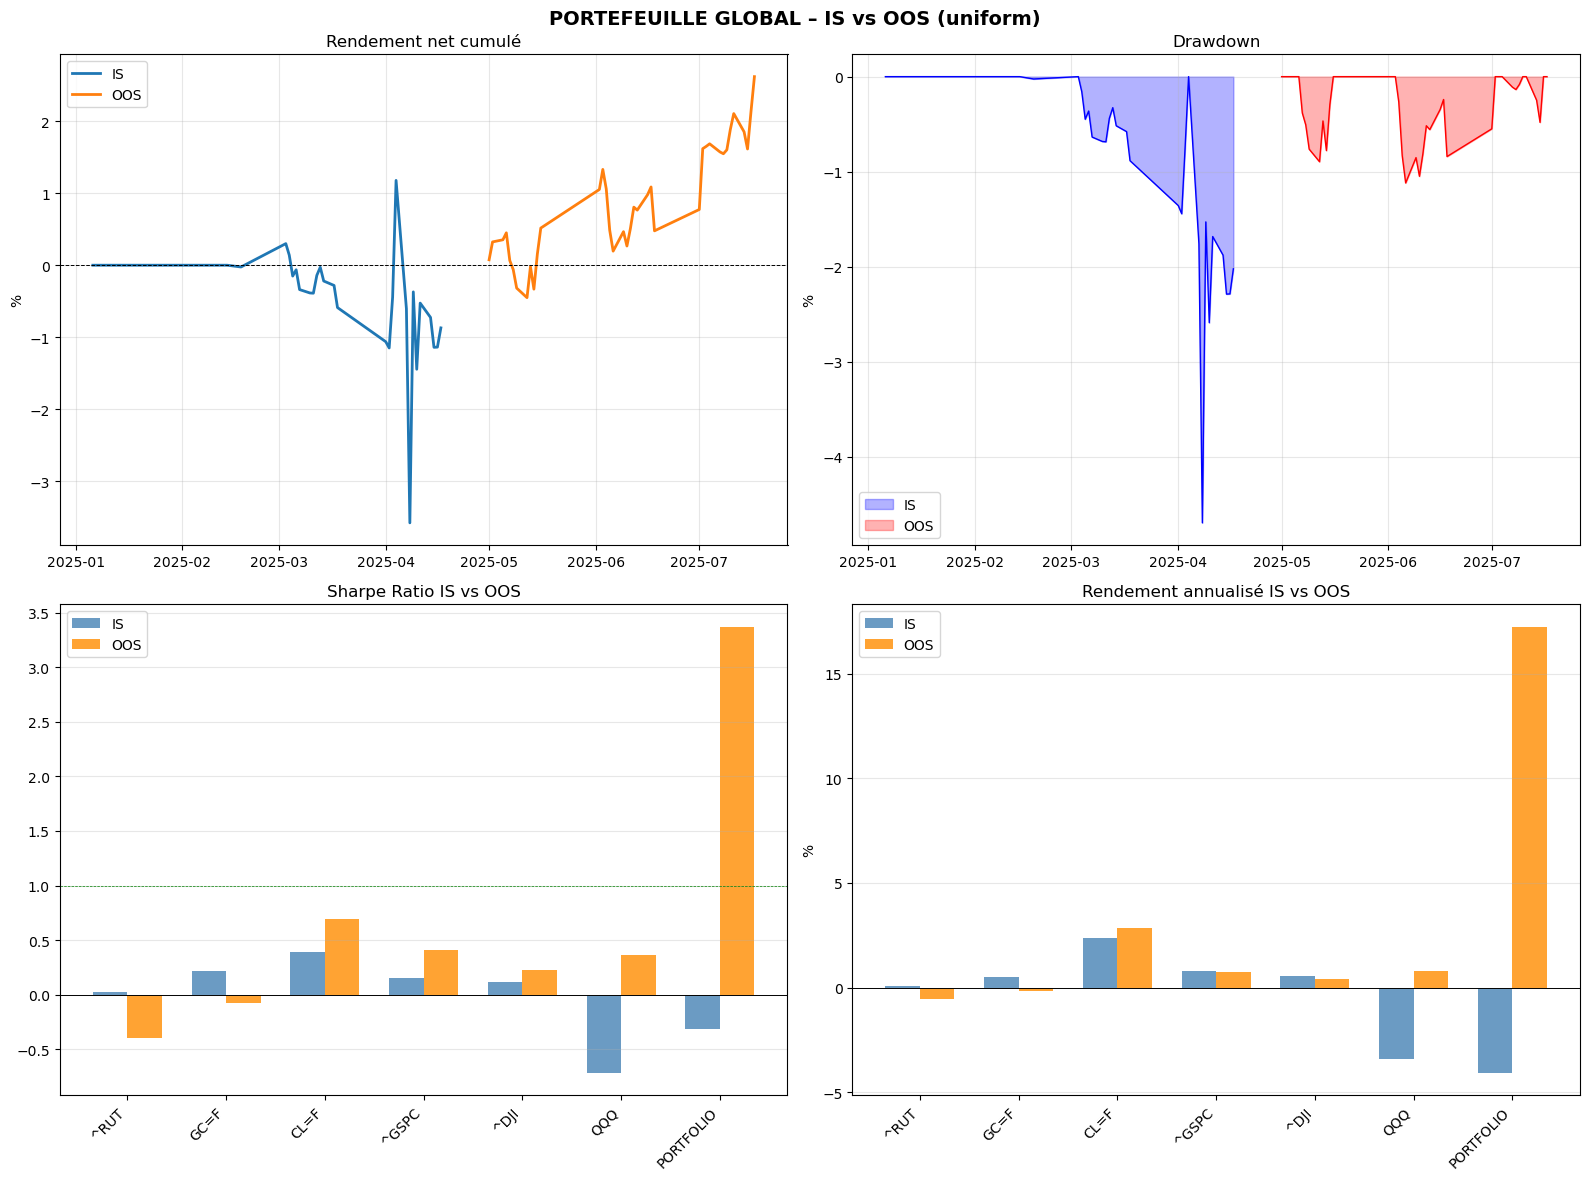

In [5]:
if __name__=="__main__":
    BASE="Data"  # folder of Yahoo 1-minute .pkl files, see README
    
    # Sous-groupe 1 : RUT
    oos1,is1=run_subgroup({'path':BASE,'portfolio':['^RUT'],'resample_freq':'15min','oos_months':3,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.002,'trailing_stop_pct_cm':0.03,
        'min_bars_between_trades':3,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':False,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.0005,0.0035,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"RUT")
    
    # Sous-groupe 2 : Commodities
    oos2,is2=run_subgroup({'path':BASE,'portfolio':['GC=F','CL=F'],'resample_freq':'15min','oos_months':3,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.002,'trailing_stop_pct_cm':0.04,
        'min_bars_between_trades':2,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':True,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.0005,0.0035,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"Commodities")
    
    # Sous-groupe 3 : Autres indices
    oos3,is3=run_subgroup({'path':BASE,'portfolio':['^GSPC','^DJI','QQQ'],'resample_freq':'15min','oos_months':3,
        'basis_point':0.0001,'use_trailing_stop':True,'trailing_stop_pct_eq':0.03,'trailing_stop_pct_cm':0.05,
        'min_bars_between_trades':2,'signal_confirmation_bars':2,'max_trades_per_day':2,
        'bear_market_filter_commodities':False,'bear_market_filter_equities':False,'optimise':True,
        'use_cross_validation':True,'min_is_bars':500,
        'grid_params':{'fast_range':[5,8,10],'slow_range':[20,30,40],'deadband_range':list(np.arange(0.001,0.01,0.0005)),
                       'trend_filter_options':[True,False],'direction_filter_options':[True,False],'sharpe_cap':3.0,'return_weight':0.3}},"Autres_Indices")
    
    # Agrégation globale avec comparaison IS vs OOS
    all_oos={**oos1,**oos2,**oos3}; all_is={**is1,**is2,**is3}
    aggregate_global(all_oos,all_is,'uniform',"Global")